<a href="https://colab.research.google.com/github/AlexBecerril/miaad-sem1/blob/main/PracticaRegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Edgar Alejandro Becerril Caballero
*   Matrícula: 275333

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [59]:
# Importar librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor



In [60]:
# Montar Google Drive para acceder al archivo del conjunto de datos.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [61]:
# Cargar el conjunto de datos advertising.csv desde Google Drive
# y mostrar las primeras observaciones para revisar su estructura.
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/datasets/advertising.csv')
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [62]:
# Se obtiene un resumen estadístico de las variables numéricas,
# incluyendo media, desviación estándar, mínimo, máximo y cuartiles.
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

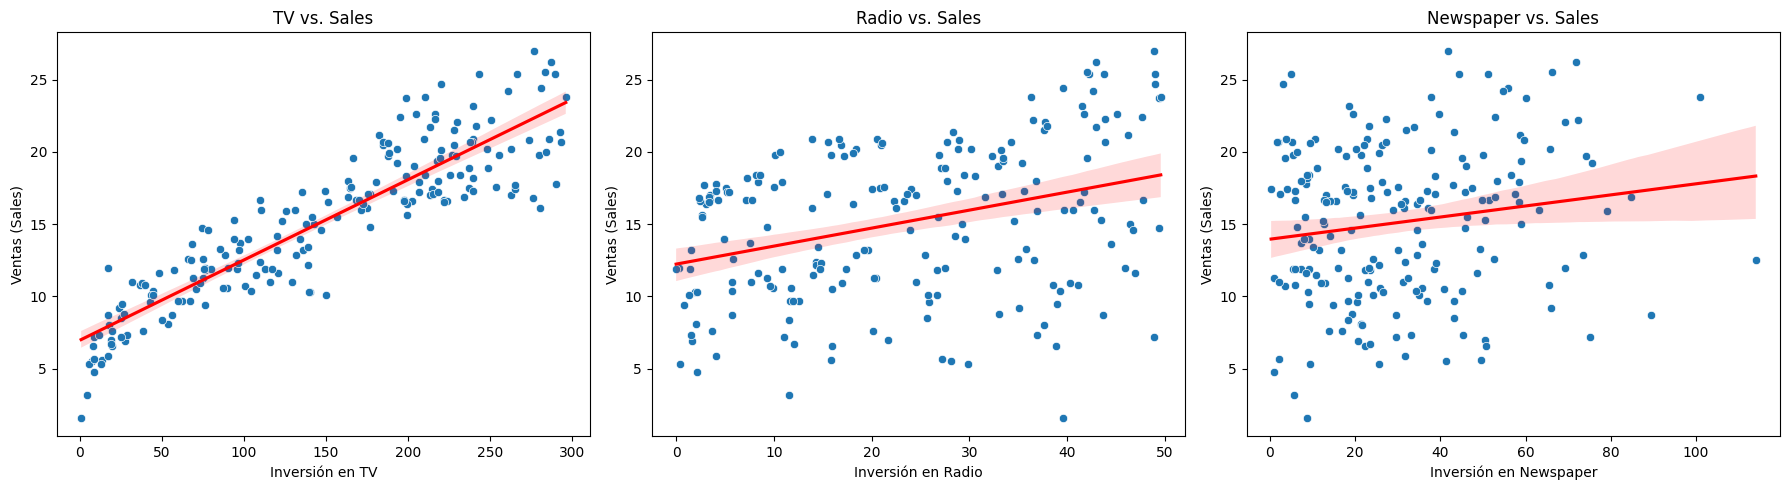

In [63]:
# Definir las variables independientes
variables = ['TV', 'Radio', 'Newspaper']

# Crear una gráfica para cada variable independiente
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, variable in enumerate(variables):

    # Graficar los puntos de dispersión
    sns.scatterplot(data=df, x=variable, y='Sales', ax=axes[i])

    # Agregar la línea de regresión lineal
    sns.regplot(
        data=df,
        x=variable,
        y='Sales',
        scatter=False,
        color='red',
        ax=axes[i]
    )

    axes[i].set_title(f'{variable} vs. Sales')
    axes[i].set_xlabel(f'Inversión en {variable}')
    axes[i].set_ylabel('Ventas (Sales)')

plt.tight_layout()
plt.show()

## Observaciones

Al analizar los diagramas de dispersión, se observa que la inversión en TV presenta una relación lineal positiva considerablemente más fuerte con las ventas (Sales), ya que los puntos se encuentran relativamente próximos a la línea de regresión. Esto sugiere que, conforme aumenta la inversión en televisión, también tienden a incrementarse las ventas.

En el caso de Radio, se identifica una tendencia positiva, aunque existe una mayor dispersión de los datos, lo que indica una relación menos fuerte. Por último, Periodico (Newspaper) presenta la mayor dispersión y una tendencia positiva más débil, por lo que visualmente parece tener una menor asociación lineal con las ventas.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

In [64]:
# Calcular la matriz de correlación entre las variables numéricas
matriz_correlacion = df[['TV', 'Radio', 'Newspaper', 'Sales']].corr()

# Mostrar la matriz de correlación
print(matriz_correlacion)

                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.901208
Radio      0.054809  1.000000   0.354104  0.349631
Newspaper  0.056648  0.354104   1.000000  0.157960
Sales      0.901208  0.349631   0.157960  1.000000


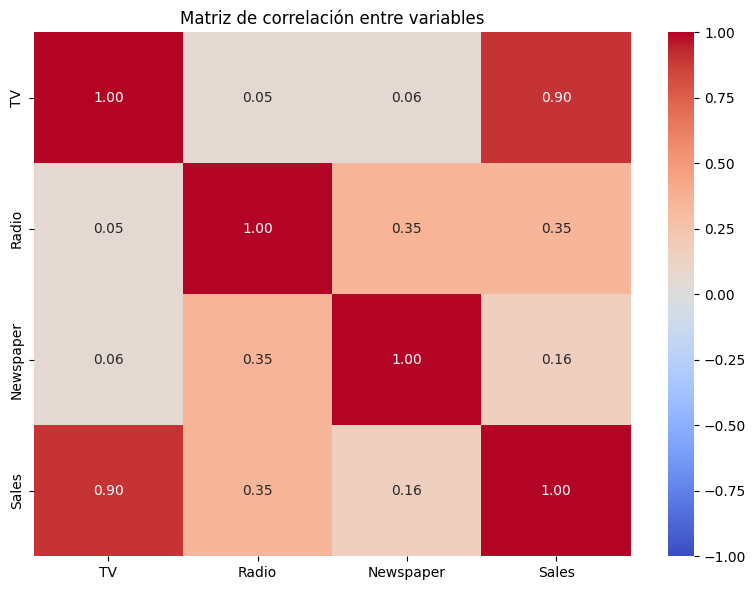

In [65]:
# Crear el mapa de calor para visualizar las correlaciones
plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_correlacion,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('Matriz de correlación entre variables')
plt.tight_layout()
plt.show()

## Observaciones

Los resultados de la matriz de correlación confirman las observaciones realizadas en las graficas de relación lineal. La inversión en TV presenta una correlación positiva muy fuerte con las ventas (0.90). Por otro lado, radio presenta una correlación positiva moderada (0.35), mientras que Periodico muestra una correlación positiva débil (0.16).

Adicionalmente, se observa que las correlaciones entre las variables independientes son relativamente bajas, destacando únicamente la relación entre radio y periodico (0.35). Esto sugiere que no existe una correlación lineal elevada entre los predictores y que, en principio, no se observa un problema importante de multicolinealidad.

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

In [66]:
# Seleccionar las variables independientes
X = df[['TV', 'Radio', 'Newspaper']]

# Calcular el VIF para cada predictor
vif_df = pd.DataFrame()
vif_df['Variable'] = X.columns
vif_df['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

# Mostrar los resultados
print(vif_df)

    Variable       VIF
0         TV  1.004611
1      Radio  1.144952
2  Newspaper  1.145187


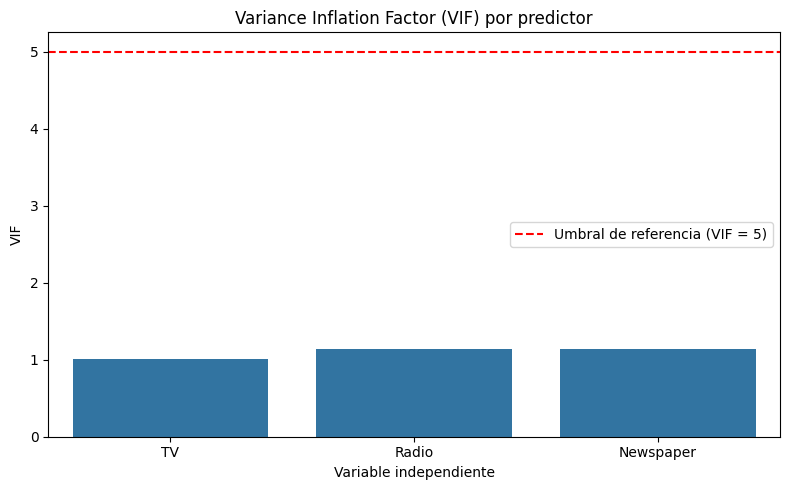

In [67]:
# Graficar el VIF de cada variable independiente
plt.figure(figsize=(8, 5))

sns.barplot(data=vif_df, x='Variable', y='VIF')

# Línea de referencia para identificar VIF elevado
plt.axhline(y=5, color='red', linestyle='--', label='Umbral de referencia (VIF = 5)')

plt.title('Variance Inflation Factor (VIF) por predictor')
plt.xlabel('Variable independiente')
plt.ylabel('VIF')
plt.legend()
plt.tight_layout()
plt.show()

## Observaciones

Al analizar el Variance Inflation Factor (VIF), se observa que las tres variables independientes presentan valores muy cercanos a 1 y considerablemente inferiores al umbral de referencia de 5. Esto indica que no existe evidencia de multicolinealidad importante entre los predictores TV, Radio y Newspaper. Por lo tanto, las variables aportan información relativamente independiente entre sí, lo que permite utilizarlas conjuntamente en el modelo de regresión lineal múltiple.

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [68]:
# Definir las variables independientes y la variable dependiente
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Imprimir el intercepto y los coeficientes
print(f'Intercepto: {modelo.intercept_:.4f}')

for variable, coeficiente in zip(X.columns, modelo.coef_):
    print(f'Coeficiente de {variable}: {coeficiente:.4f}')

Intercepto: 4.6251
Coeficiente de TV: 0.0544
Coeficiente de Radio: 0.1070
Coeficiente de Newspaper: 0.0003


## Observaciones

Al analizar el intercepto y los coeficientes del modelo de regresión lineal múltiple, se observa que el intercepto es de 4.6251, lo que representa las ventas estimadas cuando no existe inversión en ninguno de los tres medios publicitarios. Este valor se encuentra dentro del rango observado de ventas, que va de 1.6 a 27.

En cuanto a los coeficientes, TV presenta un valor de 0.0544, Radio de 0.1070 y Newspaper de 0.0003. Esto significa que, manteniendo constantes las demás variables, por cada unidad adicional de inversión en TV las ventas estimadas aumentan 0.0544 unidades; en Radio aumentan 0.1070 y en Newspaper apenas 0.0003.

Resulta interesante que Radio tenga el coeficiente más alto, aunque TV presenta la correlación individual más fuerte con las ventas. Esto demuestra que la relación individual entre dos variables no necesariamente coincide con la contribución estimada de cada predictor dentro de un modelo de regresión múltiple.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

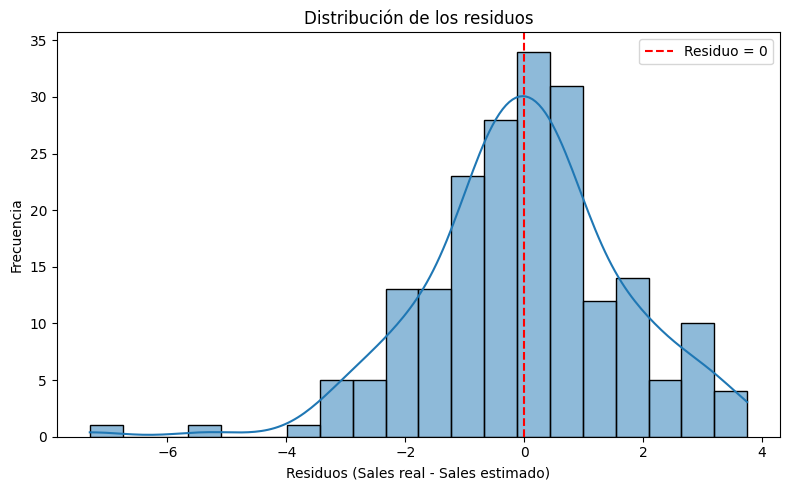

In [69]:
# Calcular las predicciones del modelo
y_pred = modelo.predict(X)

# Calcular los residuos: valores reales menos valores predichos
residuos = y - y_pred

# Graficar el histograma con la curva KDE
plt.figure(figsize=(8, 5))
sns.histplot(residuos, bins=20, kde=True)

plt.title('Distribución de los residuos')
plt.xlabel('Residuos (Sales real - Sales estimado)')
plt.ylabel('Frecuencia')
plt.axvline(x=0, color='red', linestyle='--', label='Residuo = 0')
plt.legend()
plt.tight_layout()
plt.show()

## Observaciones

Al analizar la distribución de los residuos, se observa que estos se concentran principalmente alrededor de cero y presentan una forma aproximadamente normal. Esto sugiere que el modelo no muestra un sesgo sistemático importante en sus predicciones. Sin embargo, también se identifica una ligera asimetría negativa, caracterizada por una cola hacia la izquierda y algunos valores extremos.

Debido a que los residuos se calcularon como la diferencia entre las ventas reales y las estimadas, los valores negativos indican situaciones en las que el modelo sobreestima las ventas. Por lo tanto, aunque la distribución general parece razonablemente centrada en cero, existen algunas observaciones para las cuales el modelo presenta errores de predicción considerables.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

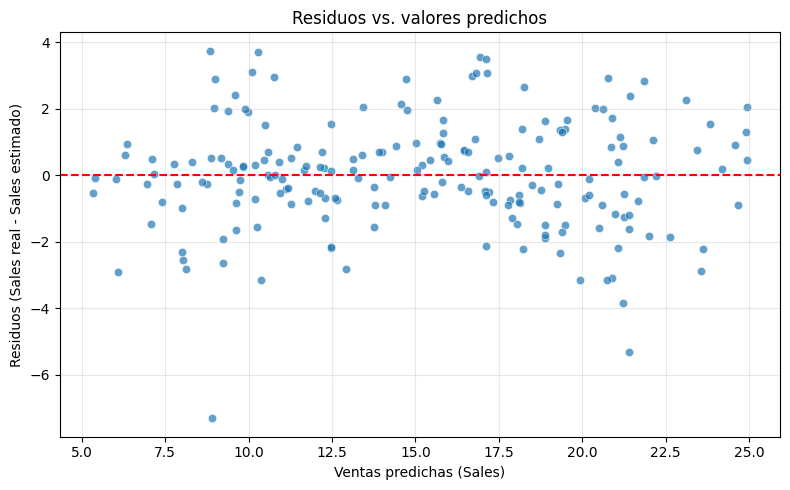

In [70]:
# Graficar los residuos contra los valores predichos
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred, y=residuos, alpha=0.7)

# Agregar una línea horizontal en cero
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residuos vs. valores predichos')
plt.xlabel('Ventas predichas (Sales)')
plt.ylabel('Residuos (Sales real - Sales estimado)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Observaciones

Al analizar la gráfica de residuos contra valores predichos, se observa que los residuos se distribuyen alrededor de cero, tanto en sentido positivo como negativo. Sin embargo, la dispersión parece incrementarse en algunos niveles de ventas estimadas, particularmente hacia los valores más altos. Esto podría indicar la presencia de heterocedasticidad, es decir, que la varianza de los errores no se mantiene constante a lo largo de las predicciones.

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

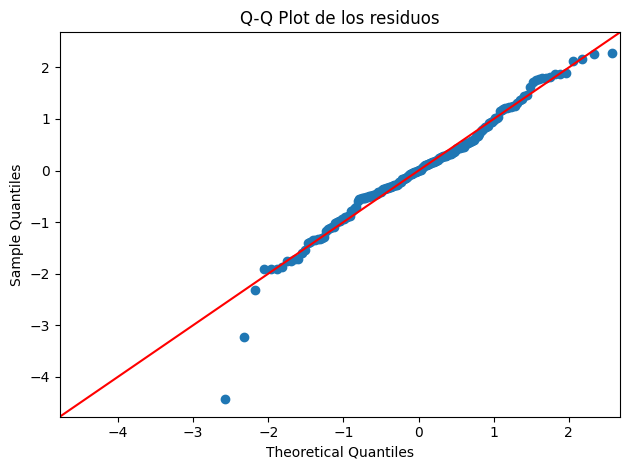

In [71]:
# Graficar los cuantiles de los residuos frente a los cuantiles teóricos normales
sm.qqplot(residuos, line='45', fit=True)

plt.title('Q-Q Plot de los residuos')
plt.tight_layout()
plt.show()

## Observaciones

Al analizar el Q-Q Plot, se observa que la mayoría de los residuos se encuentra relativamente cerca de la línea diagonal de referencia, lo que sugiere que siguen una distribución aproximadamente normal. Sin embargo, existen algunas desviaciones importantes en la cola izquierda, donde se identifican observaciones considerablemente alejadas de la línea. Esto indica la presencia de algunos residuos negativos extremos, correspondientes a casos en los que el modelo sobreestima considerablemente las ventas reales.

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [72]:
# Importar las métricas de evaluación
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Calcular el MSE
mse = mean_squared_error(y, y_pred)

# Calcular el RMSE
rmse = np.sqrt(mse)

# Calcular el R²
r2 = r2_score(y, y_pred)

# Imprimir los resultados
print(f'MSE: {mse:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'R²: {r2:.4f}')

MSE: 2.7060
RMSE: 1.6450
R²: 0.9026


## Observaciones

El modelo de regresión lineal múltiple obtuvo un MSE de 2.7060, un RMSE de 1.6450 y un R² de 0.9026. Estos resultados indican que el modelo explica aproximadamente el 90.26% de la variabilidad observada en las ventas, lo que representa una capacidad explicativa elevada. Por otra parte, el RMSE indica que la magnitud del error cuadrático medio equivale a aproximadamente 1.645 unidades de ventas, en un rango de 1.6 a 27. Estos resultados indican que el modelo presenta un ajuste bastante bueno sobre los datos analizados. No obstante, será necesario evaluar su desempeño con datos que no hayan sido utilizados durante el entrenamiento para determinar su capacidad de generalización.

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

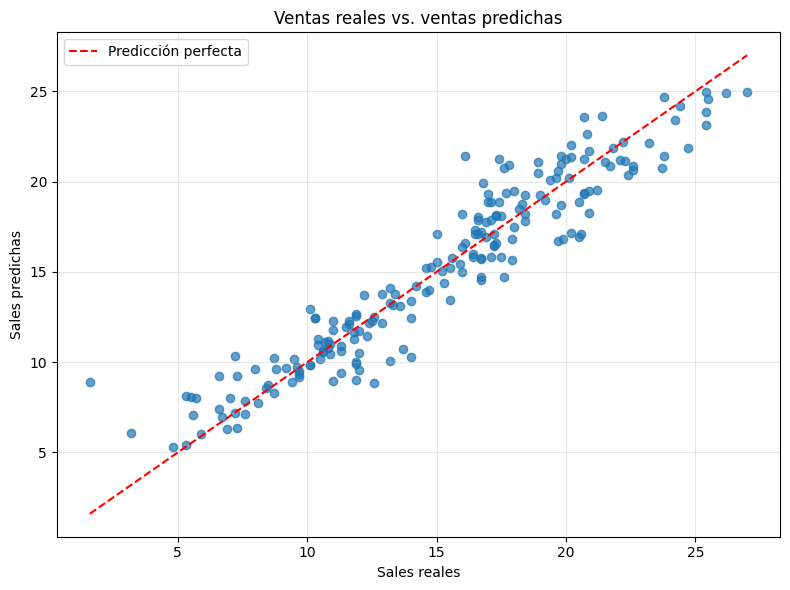

In [73]:
# Graficar los valores reales frente a los valores predichos
plt.figure(figsize=(8, 6))

plt.scatter(y, y_pred, alpha=0.7)

# Agregar una línea de referencia para predicciones perfectas
limite_min = min(y.min(), y_pred.min())
limite_max = max(y.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    color='red',
    linestyle='--',
    label='Predicción perfecta'
)

plt.title('Ventas reales vs. ventas predichas')
plt.xlabel('Sales reales')
plt.ylabel('Sales predichas')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Observaciones

Al comparar las ventas reales con las ventas predichas, se observa que la mayoría de las observaciones se encuentra relativamente cerca de la línea de predicción perfecta, lo que indica que el modelo presenta un buen ajuste.

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [74]:
# Importar la librería para construir modelos estadísticos
import statsmodels.api as sm

# Definir las variables independientes y la variable dependiente
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# Agregar la constante para estimar el intercepto
X = sm.add_constant(X)

# Ajustar el modelo de regresión lineal múltiple
modelo_sm = sm.OLS(y, X).fit()

# Mostrar el resumen estadístico del modelo
print(modelo_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        17:53:39   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

## Observaciones

Al analizar los resultados del modelo de regresión mediante Statsmodels, se observa que las variables TV y Radio presentan valores p inferiores a 0.05, por lo que ambas tienen una relación estadísticamente significativa con las ventas.

Por otro lado, Newspaper presenta un valor p de 0.954, considerablemente superior a 0.05.

En conclusión, TV y Radio son los predictores estadísticamente significativos del modelo, mientras que Newspaper no presenta una contribución significativa.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

## 5.1 Entrenamiento del Modelo (Sin Newspaper)

Después de realizar el análisis exploratorio no existe evidencia de multicolinealidad importante entre las variables independientes. Sin embargo, el análisis de significancia estadística mediante Statsmodels mostró que Newspaper no presenta una contribución estadísticamente significativa al modelo, al obtener un valor p de 0.954.

Por este motivo, se propone construir un segundo modelo eliminando dicha variable, con el propósito de comparar su desempeño frente al modelo original.

In [75]:
# Definir las variables independientes y la variable dependiente
X = df[['TV', 'Radio']]
y = df['Sales']

# Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Imprimir el intercepto y los coeficientes
print(f'Intercepto: {modelo.intercept_:.4f}')

for variable, coeficiente in zip(X.columns, modelo.coef_):
    print(f'Coeficiente de {variable}: {coeficiente:.4f}')

Intercepto: 4.6309
Coeficiente de TV: 0.0544
Coeficiente de Radio: 0.1072


## Observaciones

Al construir el modelo de regresión lineal eliminando la variable Newspaper, se obtuvieron un intercepto de 4.6309, un coeficiente de 0.0544 para TV y uno de 0.1072 para Radio.

Al comparar estos resultados con el modelo original, se observa que los coeficientes prácticamente no presentan cambios.

## 5.2 Normalidad de los residuos

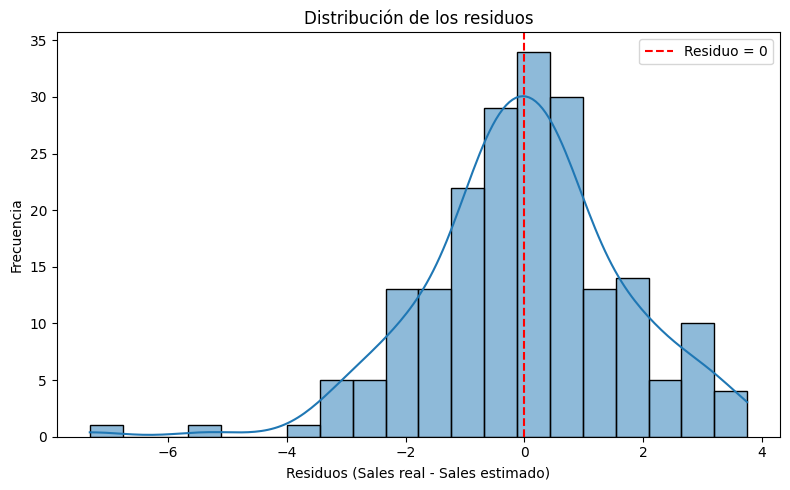

In [76]:
# Calcular las predicciones del modelo
y_pred = modelo.predict(X)

# Calcular los residuos: valores reales menos valores predichos
residuos = y - y_pred

# Graficar el histograma con la curva KDE
plt.figure(figsize=(8, 5))
sns.histplot(residuos, bins=20, kde=True)

plt.title('Distribución de los residuos')
plt.xlabel('Residuos (Sales real - Sales estimado)')
plt.ylabel('Frecuencia')
plt.axvline(x=0, color='red', linestyle='--', label='Residuo = 0')
plt.legend()
plt.tight_layout()
plt.show()

## Observaciones

Al analizar la distribución de los residuos del modelo reducido, se observa que estos se concentran principalmente alrededor de cero y presentan una forma aproximadamente normal. Sin embargo, se mantiene una asimetría negativa, caracterizada por una cola hacia la izquierda y algunos valores extremos.

## 5.3. Homocedasticidad

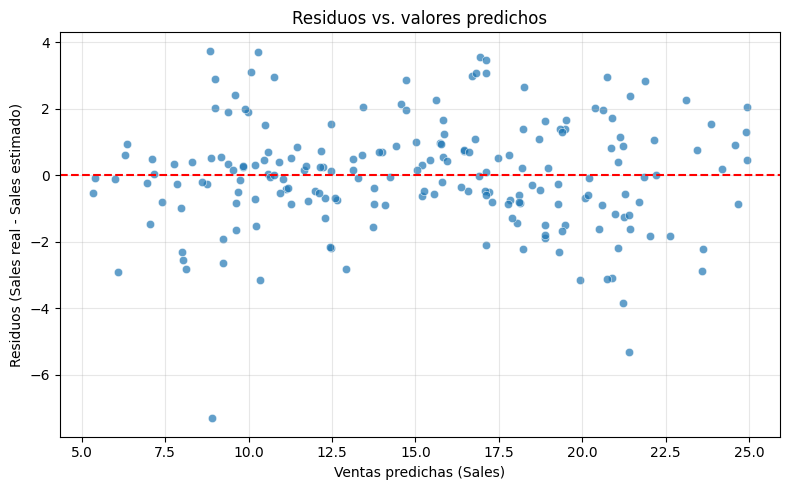

In [77]:
# Graficar los residuos contra los valores predichos
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred, y=residuos, alpha=0.7)

# Agregar una línea horizontal en cero
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residuos vs. valores predichos')
plt.xlabel('Ventas predichas (Sales)')
plt.ylabel('Residuos (Sales real - Sales estimado)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Observaciones

Al analizar la gráfica de residuos contra valores predichos del modelo reducido, se observa que los errores se distribuyen alrededor de cero, sin presentar un patrón sistemático claramente definido. Sin embargo, la dispersión de los residuos parece incrementarse en determinados niveles de ventas estimadas, al igual que en el modelo original.

## 5.4 Q-Q Plot

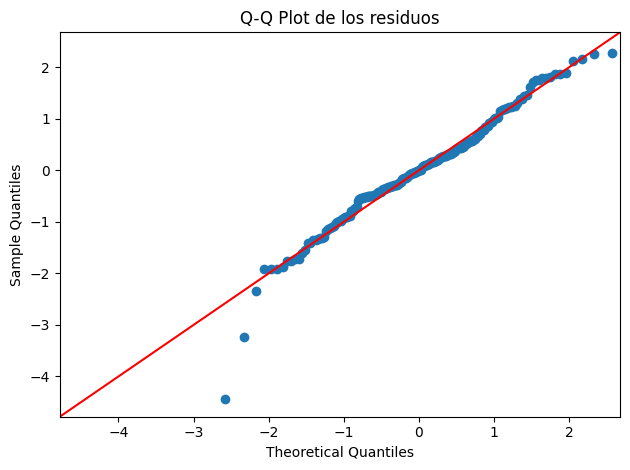

In [78]:
# Graficar los cuantiles de los residuos frente a los cuantiles teóricos normales
sm.qqplot(residuos, line='45', fit=True)

plt.title('Q-Q Plot de los residuos')
plt.tight_layout()
plt.show()

## Observaciones

Al comparar el Q-Q Plot del modelo reducido con el modelo original, se observa que ambos presentan un comportamiento prácticamente idéntico.

## 5.5. Evaluación del Modelo

In [79]:
# Importar las métricas de evaluación
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Calcular el MSE
mse = mean_squared_error(y, y_pred)

# Calcular el RMSE
rmse = np.sqrt(mse)

# Calcular el R²
r2 = r2_score(y, y_pred)

# Imprimir los resultados
print(f'MSE: {mse:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'R²: {r2:.4f}')

MSE: 2.7061
RMSE: 1.6450
R²: 0.9026


## Observaciones

Al evaluar el modelo reducido, se obtuvo un MSE de 2.7061, un RMSE de 1.6450 y un R² de 0.9026. Al comparar estos resultados con el modelo original, se observa que las métricas permanecen prácticamente idénticas, con diferencias insignificantes.

## 5.6. Visualización de Predicciones

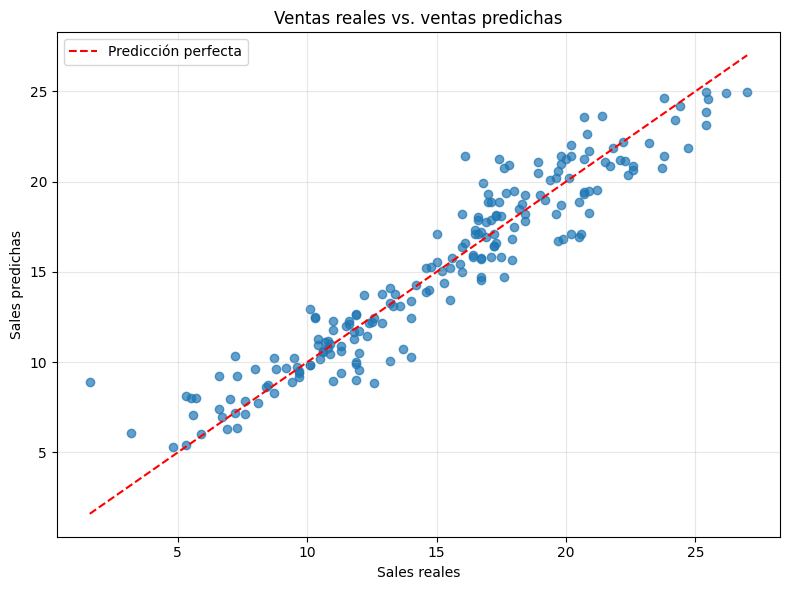

In [80]:
# Graficar los valores reales frente a los valores predichos
plt.figure(figsize=(8, 6))

plt.scatter(y, y_pred, alpha=0.7)

# Agregar una línea de referencia para predicciones perfectas
limite_min = min(y.min(), y_pred.min())
limite_max = max(y.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    color='red',
    linestyle='--',
    label='Predicción perfecta'
)

plt.title('Ventas reales vs. ventas predichas')
plt.xlabel('Sales reales')
plt.ylabel('Sales predichas')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Observaciones

Al comparar las ventas reales con las ventas predichas del modelo reducido, se observa que la mayoría de las observaciones se mantiene relativamente cerca de la línea de predicción perfecta, lo que indica un buen ajuste entre los valores estimados y los reales.

## 5.7 Verificar el impacto de los atributos en el modelo

In [81]:
# Importar la librería para construir modelos estadísticos
import statsmodels.api as sm

# Definir las variables independientes y la variable dependiente
X = df[['TV', 'Radio']]
y = df['Sales']

# Agregar la constante para estimar el intercepto
X = sm.add_constant(X)

# Ajustar el modelo de regresión lineal múltiple
modelo_sm = sm.OLS(y, X).fit()

# Mostrar el resumen estadístico del modelo
print(modelo_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        17:53:40   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.0

## Observaciones

Al analizar el impacto de los atributos mediante Statsmodels, se observa que tanto TV como Radio presentan coeficientes positivos y valores p inferiores a 0.05, por lo que ambas variables tienen una contribución estadísticamente significativa para explicar las ventas.

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

## 6.1 Entrenamiento del Modelo (Solo TV)

En esta tercera etapa se construirá un modelo de regresión lineal simple utilizando únicamente la inversión en televisión (TV) como variable independiente para predecir las ventas (Sales).

La decisión de utilizar este predictor se basa en el análisis exploratorio y la matriz de correlación realizados anteriormente, donde TV presentó la relación lineal positiva más fuerte con las ventas, con un coeficiente de correlación de 0.90.

El objetivo es evaluar qué tanta capacidad explicativa conserva el modelo utilizando un solo predictor y determinar si esta variable, por sí misma, permite realizar estimaciones suficientemente precisas.

In [82]:
# Definir las variables independientes y la variable dependiente
X = df[['TV']]
y = df['Sales']

# Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Imprimir el intercepto y los coeficientes
print(f'Intercepto: {modelo.intercept_:.4f}')

for variable, coeficiente in zip(X.columns, modelo.coef_):
    print(f'Coeficiente de {variable}: {coeficiente:.4f}')

Intercepto: 6.9748
Coeficiente de TV: 0.0555


## Observaciones

Al construir el modelo de regresión lineal utilizando únicamente TV como variable independiente, se obtuvo un intercepto de 6.9748 y un coeficiente de 0.0555.

Al comparar este resultado con el modelo anterior, que también incluía Radio, se observa que el coeficiente de TV presenta un ligero incremento, pasando de 0.0544 a 0.0555. Esto indica que, al considerar únicamente la inversión en televisión, se mantiene una relación positiva con las ventas.

## 6.2 Normalidad de los residuos

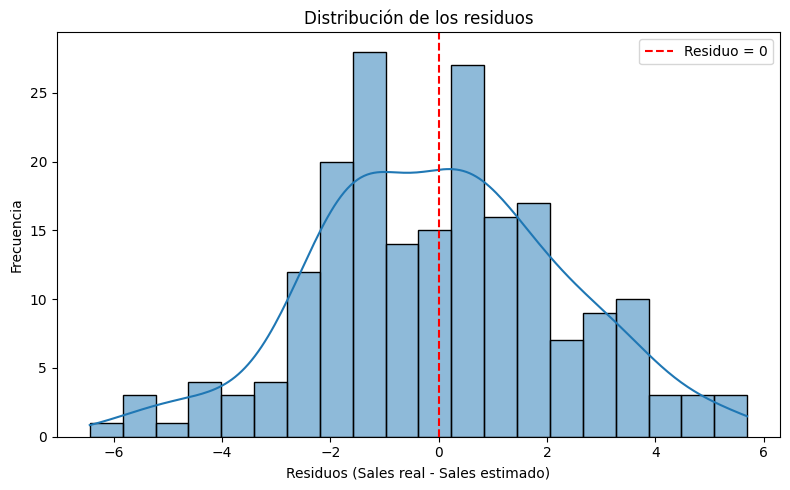

In [83]:
# Calcular las predicciones del modelo
y_pred = modelo.predict(X)

# Calcular los residuos: valores reales menos valores predichos
residuos = y - y_pred

# Graficar el histograma con la curva KDE
plt.figure(figsize=(8, 5))
sns.histplot(residuos, bins=20, kde=True)

plt.title('Distribución de los residuos')
plt.xlabel('Residuos (Sales real - Sales estimado)')
plt.ylabel('Frecuencia')
plt.axvline(x=0, color='red', linestyle='--', label='Residuo = 0')
plt.legend()
plt.tight_layout()
plt.show()

## Observaciones

Al analizar la distribución de los residuos del tercer modelo, construido únicamente con la variable TV, se observa que estos continúan concentrándose alrededor de cero. Sin embargo, la distribución presenta una forma menos cercana a una campana normal en comparación con los modelos anteriores, mostrando una mayor irregularidad y dispersión en sus extremos.

## 6.3. Homocedasticidad

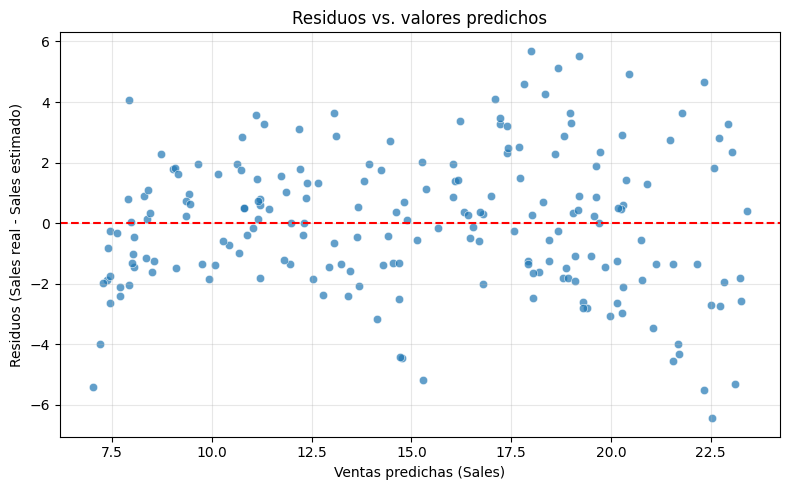

In [84]:
# Graficar los residuos contra los valores predichos
plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_pred, y=residuos, alpha=0.7)

# Agregar una línea horizontal en cero
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residuos vs. valores predichos')
plt.xlabel('Ventas predichas (Sales)')
plt.ylabel('Residuos (Sales real - Sales estimado)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Observaciones

Al analizar la gráfica de residuos contra valores predichos del tercer modelo, se observa que los errores se distribuyen alrededor de cero, aunque presentan una dispersión creciente conforme aumentan las ventas estimadas.

## 6.4 Q-Q Plot

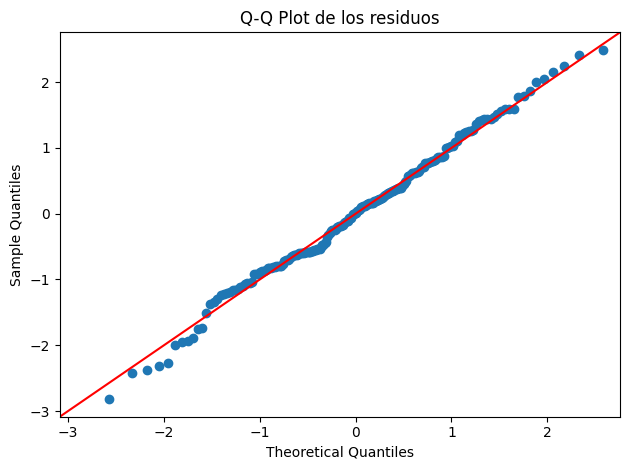

In [85]:
# Graficar los cuantiles de los residuos frente a los cuantiles teóricos normales
sm.qqplot(residuos, line='45', fit=True)

plt.title('Q-Q Plot de los residuos')
plt.tight_layout()
plt.show()

## Observaciones

Al comparar este resultado con los modelos anteriores, se observa una mejor alineación de los puntos con la diagonal, particularmente en los extremos. Esto sugiere que el modelo que utiliza únicamente TV presenta un comportamiento más cercano a la normalidad en sus residuos.

## 6.5. Evaluación del Modelo

In [86]:
# Importar las métricas de evaluación
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Calcular el MSE
mse = mean_squared_error(y, y_pred)

# Calcular el RMSE
rmse = np.sqrt(mse)

# Calcular el R²
r2 = r2_score(y, y_pred)

# Imprimir los resultados
print(f'MSE: {mse:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'R²: {r2:.4f}')

MSE: 5.2177
RMSE: 2.2842
R²: 0.8122


## Observaciones

Al evaluar el tercer modelo, construido únicamente con la variable TV, se obtuvo un MSE de 5.2177, un RMSE de 2.2842 y un R² de 0.8122. Esto indica que el modelo explica aproximadamente el 81.22% de la variabilidad observada en las ventas.

Al comparar estos resultados con los dos modelos anteriores, se observa una disminución de aproximadamente 9.04 puntos porcentuales en el R² y un incremento del error de predicción. Esto sugiere que, aunque TV presenta una correlación individual muy fuerte con las ventas, no es suficiente por sí sola para conservar toda la capacidad explicativa del modelo.

## 6.6. Visualización de Predicciones

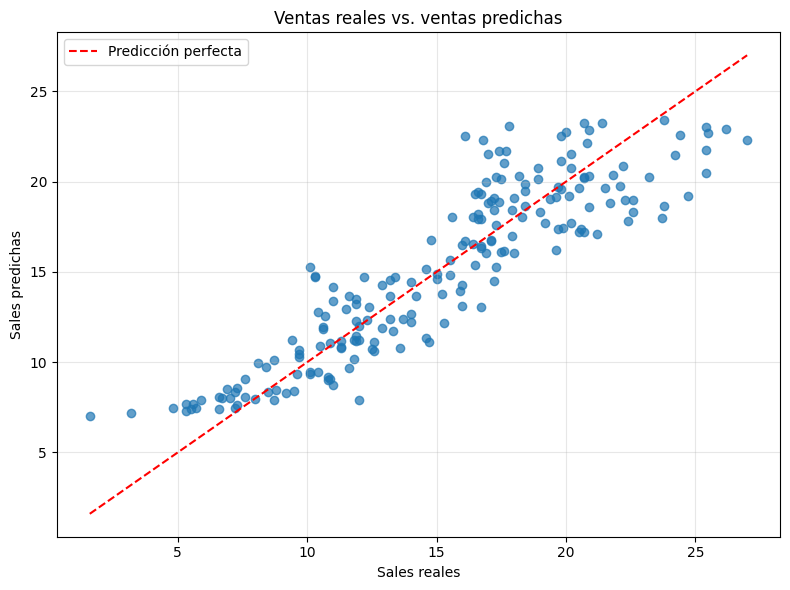

In [87]:
# Graficar los valores reales frente a los valores predichos
plt.figure(figsize=(8, 6))

plt.scatter(y, y_pred, alpha=0.7)

# Agregar una línea de referencia para predicciones perfectas
limite_min = min(y.min(), y_pred.min())
limite_max = max(y.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    color='red',
    linestyle='--',
    label='Predicción perfecta'
)

plt.title('Ventas reales vs. ventas predichas')
plt.xlabel('Sales reales')
plt.ylabel('Sales predichas')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Observaciones

Al comparar las ventas reales con las ventas predichas del tercer modelo, se observa que existe una tendencia positiva, aunque los puntos presentan una mayor dispersión respecto a la línea de predicción perfecta en comparación con los modelos anteriores.

## 6.7 Verificar el impacto de los atributos en el modelo

In [88]:
# Importar la librería para construir modelos estadísticos
import statsmodels.api as sm

# Definir las variables independientes y la variable dependiente
X = df[['TV']]
y = df['Sales']

# Agregar la constante para estimar el intercepto
X = sm.add_constant(X)

# Ajustar el modelo de regresión lineal múltiple
modelo_sm = sm.OLS(y, X).fit()

# Mostrar el resumen estadístico del modelo
print(modelo_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.812
Model:                            OLS   Adj. R-squared:                  0.811
Method:                 Least Squares   F-statistic:                     856.2
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           7.93e-74
Time:                        17:53:41   Log-Likelihood:                -448.99
No. Observations:                 200   AIC:                             902.0
Df Residuals:                     198   BIC:                             908.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.9748      0.323     21.624      0.0

## Observaciones

Al analizar el impacto de la variable TV mediante Statsmodels, se observa que presenta un coeficiente positivo de 0.0555 y un valor p inferior a 0.05, por lo que existe evidencia estadística de una relación significativa con las ventas.

##7. Conclusiones.

**¿Cuál de los tres modelos construidos fue el mejor?**

El segundo modelo, compuesto por TV y Radio, presentó el mejor equilibrio entre simplicidad y capacidad explicativa.

**¿Cuál fue el atributo que mas influencia tiene en las ventas?**

La inversión en TV fue el atributo con mayor asociación individual con las ventas, presentando una correlación de 0.90, considerablemente superior a Radio (0.35) y Newspaper (0.16).